## Data Cleaning and Wrangling

In [ ]:
#Imports
import altair as alt
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn import set_config
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate,
    train_test_split,
)
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score


# Some are unnecessary (come back after finishing to eliminate ones we didn't use


In [ ]:
import pandas as pd

# Reading in the dataset
encounters = pd.read_csv("encounters.csv")
diagnosis = pd.read_csv("diagnosis.csv")
patients = pd.read_csv("patients.csv")

# Select necessary columns
encounters = encounters[[
    "EncounterKey",
    "PatientDurableKey",
    "PrimaryDiagnosisKey",
    "Date",
    "IsEdVisit",
    "IsHospitalAdmission",
    "IsInpatientAdmission",
    "IsOutpatientFaceToFaceVisit",
    "Type",
    "VisitType",
    "VisitTypeDescription",
    "DepartmentKey"
]].copy()

diagnosis = diagnosis[[
    "DiagnosisKey",
    "DiagnosisValue",
    "DiagnosisName",
    "GroupCode",
    "GroupName"
]].copy()

patients = patients[[
    "DurableKey",
    "MyChartStatus",
    "PatientBirthYearBin",
    "SexAssignedAtBirth",
    "SmokingStatus",
    "FirstRace",
    "OmbEthnicity"
]].copy()

# Clean date column
encounters["Date"] = pd.to_datetime(encounters["Date"], errors="coerce")

# Check missing dates after conversion
print("Missing Date after conversion:", encounters["Date"].isna().sum())

# Optional: make boolean-like columns consistent
bool_cols = [
    "IsEdVisit",
    "IsHospitalAdmission",
    "IsInpatientAdmission",
    "IsOutpatientFaceToFaceVisit"
]

for col in bool_cols:
    encounters[col] = encounters[col].replace({
        "TRUE": True, "FALSE": False,
        "True": True, "False": False,
        1: True, 0: False
    })

# Drop rows missing essential keys
encounters = encounters.dropna(subset=[
    "EncounterKey",
    "PatientDurableKey",
    "PrimaryDiagnosisKey",
    "Date"
])

diagnosis = diagnosis.dropna(subset=[
    "DiagnosisKey",
    "DiagnosisValue"
])

patients = patients.dropna(subset=[
    "DurableKey"
])

# Remove duplicates by key
encounters = encounters.drop_duplicates(subset=["EncounterKey"])
diagnosis = diagnosis.drop_duplicates(subset=["DiagnosisKey"])
patients = patients.drop_duplicates(subset=["DurableKey"])

# Quick checks
print("Encounters shape:", encounters.shape)
print("Diagnosis shape:", diagnosis.shape)
print("Patients shape:", patients.shape)


Missing Date after conversion: 0

Encounters shape: (7675801, 12)
Diagnosis shape: (1382555, 5)
Patients shape: (947685, 7)

In [ ]:
# Merge encounters + diagnosis
df = encounters.merge(
    diagnosis,
    left_on="PrimaryDiagnosisKey",
    right_on="DiagnosisKey",
    how="left"
)

# Merge patient info
df = df.merge(
    patients,
    left_on="PatientDurableKey",
    right_on="DurableKey",
    how="left"
)

# 9. Keep final useful columns
df = df[[
    "EncounterKey",
    "PatientDurableKey",
    "Date",
    "IsEdVisit",
    "IsHospitalAdmission",   
    "IsInpatientAdmission", 
    "IsOutpatientFaceToFaceVisit",
    "Type",
    "VisitType",
    "VisitTypeDescription",
    "DiagnosisValue",
    "DiagnosisName",
    "GroupCode",
    "GroupName",
    "MyChartStatus",
    "PatientBirthYearBin",
    "SexAssignedAtBirth",
    "SmokingStatus",
    "FirstRace",
    "OmbEthnicity"
]].copy()

print(df.head())


## First Analysis

In [ ]:
# Make sure Date is datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Drop rows missing key fields needed for journey analysis
df = df.dropna(subset=["PatientDurableKey", "DiagnosisValue", "Date"]).copy()

# Sort by patient + diagnosis + date
df = df.sort_values(
    ["PatientDurableKey", "DiagnosisValue", "Date", "EncounterKey"]
).copy()

# Find next visit for same patient + same diagnosis
group_cols = ["PatientDurableKey", "DiagnosisValue"]

df["NextDate"] = df.groupby(group_cols)["Date"].shift(-1)
df["NextVisitType"] = df.groupby(group_cols)["VisitTypeDescription"].shift(-1)
df["NextEncounterKey"] = df.groupby(group_cols)["EncounterKey"].shift(-1)

# Compute delay in days
df["DelayDays"] = (df["NextDate"] - df["Date"]).dt.days

# Keep only serious visits
# (requires these columns to exist in df)
required_cols = ["IsEdVisit", "IsHospitalAdmission", "IsInpatientAdmission"]
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise KeyError(
        f"Missing required columns in df: {missing_cols}. "
        "Go back and keep them from encounters before merging."
    )

analysis_df = df[
    (df["IsInpatientAdmission"] == True) |
    ((df["IsEdVisit"] == True) & (df["IsHospitalAdmission"] == True))
].copy()

# Create follow-up flags
analysis_df["HasFollowUp"] = analysis_df["NextDate"].notna()

# delayed only among those with a follow-up date
analysis_df["Delayed"] = analysis_df["DelayDays"] > 30

# delay category
def classify_delay(days):
    if pd.isna(days):
        return "No follow-up"
    elif days <= 7:
        return "0-7 days"
    elif days <= 30:
        return "8-30 days"
    else:
        return "31+ days"

analysis_df["DelayCategory"] = analysis_df["DelayDays"].apply(classify_delay)

# Sanity checks
print("Analysis dataset shape:", analysis_df.shape)
print("Negative delays:", (analysis_df["DelayDays"] < 0).sum())
print("Zero-day delays:", (analysis_df["DelayDays"] == 0).sum())

print("\nSample rows:")
print(
    analysis_df[
        [
            "EncounterKey",
            "PatientDurableKey",
            "DiagnosisValue",
            "Date",
            "NextDate",
            "NextVisitType",
            "DelayDays",
            "DelayCategory"
        ]
    ].head(10)
)

# Summary statistics
print("\nDelay category counts:")
print(analysis_df["DelayCategory"].value_counts(dropna=False))

print("\nNo follow-up %:",
      (~analysis_df["HasFollowUp"]).mean() * 100)

print("Delayed (>30 days) %:",
      analysis_df["Delayed"].mean() * 100)

print("Average delay among those with follow-up:",
      analysis_df.loc[analysis_df["HasFollowUp"], "DelayDays"].mean())

print("Median delay among those with follow-up:",
      analysis_df.loc[analysis_df["HasFollowUp"], "DelayDays"].median())


Analysis dataset shape: (94733, 27)
Negative delays: 0
Zero-day delays: 572

Delay category counts:
DelayCategory
No follow-up    75141
31+ days        10053
8-30 days        6594
0-7 days         2945
Name: count, dtype: int64

No follow-up %: 79.31871681462637
Delayed (>30 days) %: 10.611930372731782
Average delay among those with follow-up: 119.29404859126174
Median delay among those with follow-up: 33.0

## First Visualization

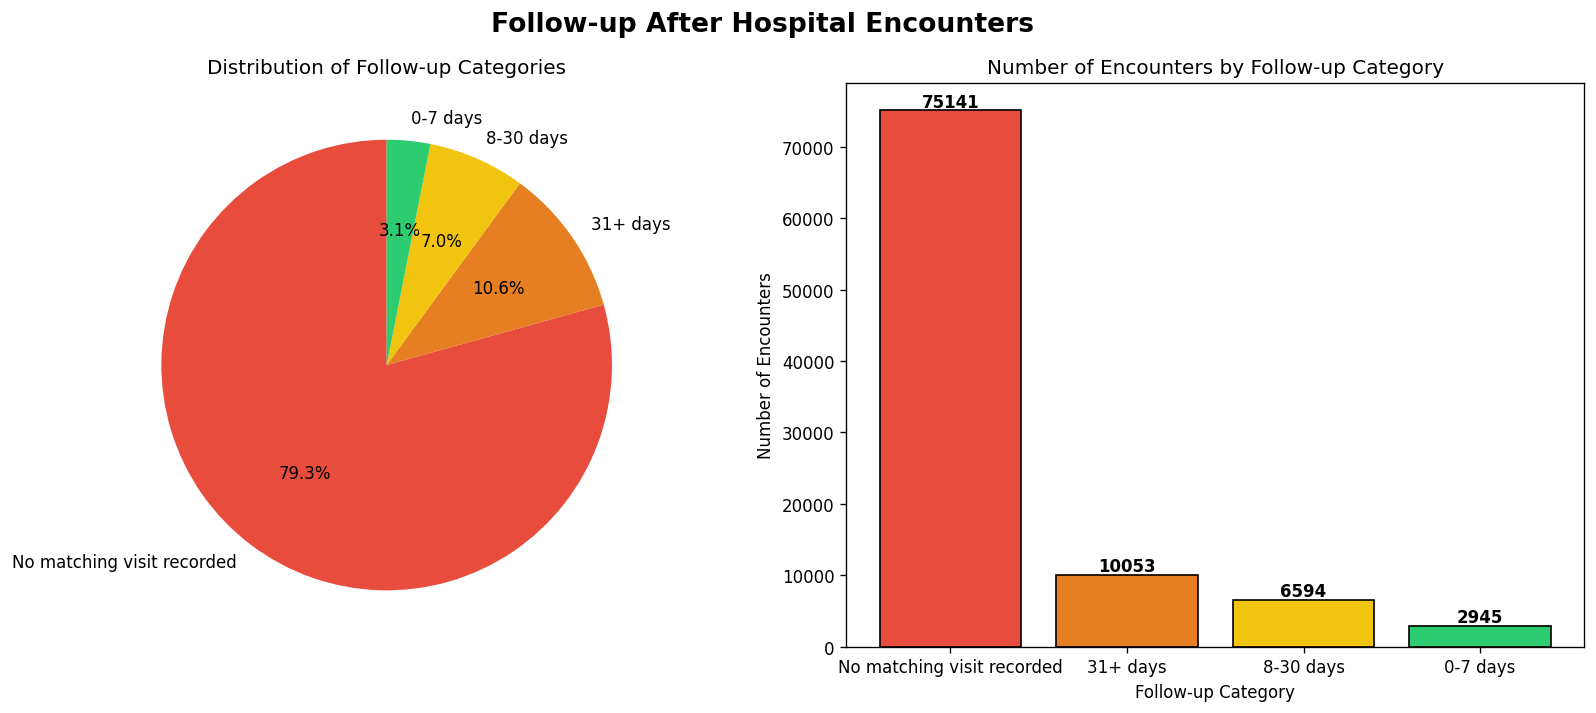

Key Statistics:
No matching visit recorded: 79.3% of encounters
Average delay (those with follow-up): 119.3 days
Median delay (those with follow-up): 33.0 days

In [ ]:
# Follow-up overview
import numpy as np

# Data
categories = ['No matching visit recorded', '31+ days', '8-30 days', '0-7 days']
counts = [75141, 10053, 6594, 2945]
colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Follow-up After Hospital Encounters', fontsize=16, fontweight='bold')

# Pie chart
axes[0].pie(counts, labels=categories, colors=colors, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Distribution of Follow-up Categories')

# Bar chart
bars = axes[1].bar(categories, counts, color=colors, edgecolor='black')
axes[1].set_title('Number of Encounters by Follow-up Category')
axes[1].set_xlabel('Follow-up Category')
axes[1].set_ylabel('Number of Encounters')
for bar, count in zip(bars, counts):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                str(count), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('followup_overview.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nKey Statistics:")
print(f"No matching visit recorded: 79.3% of encounters")
print(f"Average delay (those with follow-up): 119.3 days")
print(f"Median delay (those with follow-up): 33.0 days")


## Machine Learning

## Predicting delayed or unrecorded follow-up

In [ ]:
analysis_df = pd.read_csv("analysis_df.csv")
sd = pd.read_csv("social_determinants.csv", dtype=str)

print("analysis_df shape:", analysis_df.shape)
print("sd shape:", sd.shape)

display(analysis_df.head())
print(analysis_df["DelayCategory"].value_counts(dropna=False))


analysis_df shape: (94733, 27)
sd shape: (3977901, 5)

DelayCategory
No follow-up    75141
31+ days        10053
8-30 days        6594
0-7 days         2945
Name: count, dtype: int64

In [ ]:
analysis_df


In [ ]:
analysis_df.info()


## 1. Define the ML target clearly

In [ ]:
model_df = analysis_df.copy()

# 1 = delayed OR no follow-up
# 0 = fast / moderate follow-up
model_df["DelayedOrNone"] = model_df["DelayCategory"].isin(
    ["No follow-up", "31+ days"]
).astype(int)

print(model_df["DelayedOrNone"].value_counts())
print(model_df["DelayedOrNone"].value_counts(normalize=True))


DelayedOrNone
1    85194
0     9539
Name: count, dtype: int64
DelayedOrNone
1    0.899306
0    0.100694
Name: proportion, dtype: float64

In [ ]:
print(model_df.columns)


## 2. Build patient-level SDOH flags

In [ ]:
sd_ml = sd.copy()

sd_ml["PatientDurableKey"] = pd.to_numeric(sd_ml["PatientDurableKey"], errors="coerce")
sd_ml = sd_ml.dropna(subset=["PatientDurableKey"]).copy()

for col in ["Domain", "DisplayName", "AnswerText"]:
    sd_ml[col] = sd_ml[col].astype(str).str.strip()

sd_ml["AnswerText"] = sd_ml["AnswerText"].str.lower()

print(sd_ml["Domain"].value_counts(dropna=False).head(30))
print(sd_ml["DisplayName"].value_counts(dropna=False).head(50))
print(sd_ml["AnswerText"].value_counts(dropna=False).head(30))


In [ ]:
# Transportation barrier

transport_keys = sd_ml[
    sd_ml["Domain"].str.contains("transport", case=False, na=False) &
    sd_ml["AnswerText"].isin(["yes", "often", "sometimes"])
]["PatientDurableKey"].unique()

# Financial barrier

finance_keys = sd_ml[
    sd_ml["Domain"].str.contains("financial|finance", case=False, na=False) &
    sd_ml["AnswerText"].isin(["yes", "often", "sometimes"])
]["PatientDurableKey"].unique()

# Create patient-level SDOH table

sd_patients = pd.DataFrame({
    "PatientDurableKey": sd_ml["PatientDurableKey"].dropna().unique()
})

sd_patients["transport_barrier"] = sd_patients["PatientDurableKey"].isin(transport_keys).astype(int)
sd_patients["financial_barrier"] = sd_patients["PatientDurableKey"].isin(finance_keys).astype(int)

display(sd_patients.head())
print(sd_patients[["transport_barrier", "financial_barrier"]].sum())


In [ ]:
# Merge SDOH into model table

model_df = model_df.merge(
    sd_patients,
    on="PatientDurableKey",
    how="left"
)

model_df["transport_barrier"] = model_df["transport_barrier"].fillna(0).astype(int)
model_df["financial_barrier"] = model_df["financial_barrier"].fillna(0).astype(int)

print(model_df[["transport_barrier", "financial_barrier"]].sum())


transport_barrier    5790
financial_barrier    6415
dtype: int64

In [ ]:
# Add engagement feature (MyChart proxy)

model_df["engaged"] = model_df["MyChartStatus"].apply(
    lambda x: 1 if str(x).lower() == "activated" else 0
)

# Check distribution
print(model_df["engaged"].value_counts())

print("\nEngagement vs delay:")
print(model_df.groupby("engaged")["DelayedOrNone"].mean())


engaged
1    60702
0    34031
Name: count, dtype: int64

Engagement vs delay:
engaged
0    0.922071
1    0.886544
Name: DelayedOrNone, dtype: float64

## 3. Clean and strengthen features

In [ ]:
# birth year
model_df["PatientBirthYearBin"] = pd.to_numeric(
    model_df["PatientBirthYearBin"],
    errors="coerce"
)

# cast bool-like columns if present
bool_cols = ["IsEdVisit", "IsHospitalAdmission", "IsInpatientAdmission"]
for col in bool_cols:
    if col in model_df.columns:
        model_df[col] = model_df[col].astype(int)

# quick missingness check
candidate_check_cols = [
    "transport_barrier", "financial_barrier", "engaged",
    "PatientBirthYearBin", "IsEdVisit", "IsHospitalAdmission", "IsInpatientAdmission",
    "SexAssignedAtBirth", "SmokingStatus", "FirstRace", "OmbEthnicity", "GroupName"
]
candidate_check_cols = [c for c in candidate_check_cols if c in model_df.columns]

missing = pd.DataFrame({
    "missing_n": model_df[candidate_check_cols].isna().sum(),
    "missing_pct": model_df[candidate_check_cols].isna().mean() * 100
}).sort_values("missing_pct", ascending=False)

display(missing)


## Simplify diagnosis groups

In [ ]:
# keep top diagnosis groups, collapse the rest into "Other"
top_groups = model_df["GroupName"].value_counts(dropna=False).head(10).index.tolist()

model_df["GroupName_simplified"] = model_df["GroupName"].apply(
    lambda x: x if x in top_groups else "Other"
)

print(model_df["GroupName_simplified"].value_counts())


GroupName_simplified
Other                                                                                                       62199
Other sepsis                                                                                                 7818
Liveborn infants according to place of birth and type of delivery                                            6897
Major depressive disorder, recurrent                                                                         5197
Atrial fibrillation and flutter                                                                              2431
Respiratory failure, not elsewhere classified                                                                2154
Bipolar disorder                                                                                             1963
Hypertensive heart disease                                                                                   1564
Type 2 diabetes mellitus                                           

## Build feature set

In [ ]:
feature_cols = [
    "transport_barrier",
    "financial_barrier",
    "engaged",
    "PatientBirthYearBin",
    "IsEdVisit",
    "IsHospitalAdmission",
    "IsInpatientAdmission",
    "SexAssignedAtBirth",
    "SmokingStatus",
    "FirstRace",
    "OmbEthnicity",
    "GroupName_simplified"
]

feature_cols = [c for c in feature_cols if c in model_df.columns]

X = model_df[feature_cols].copy()
y = model_df["DelayedOrNone"].copy()

print("Feature columns:")
print(feature_cols)
display(X.head())


## 4. Split train/test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)


(75786, 12) (18947, 12)

## 5. Preprocess features

In [ ]:
numeric_cols = [
    "transport_barrier",
    "financial_barrier",
    "engaged",
    "PatientBirthYearBin",
    "IsEdVisit",
    "IsHospitalAdmission",
    "IsInpatientAdmission"
]
numeric_cols = [c for c in numeric_cols if c in X.columns]

categorical_cols = [c for c in X.columns if c not in numeric_cols]

print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)


Numeric: ['transport_barrier', 'financial_barrier', 'engaged', 'PatientBirthYearBin', 'IsEdVisit', 'IsHospitalAdmission', 'IsInpatientAdmission']
Categorical: ['SexAssignedAtBirth', 'SmokingStatus', 'FirstRace', 'OmbEthnicity', 'GroupName_simplified']

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ]
)


## 6. Train model: Random Forest

In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)


## 7. Evaluate Model

In [ ]:
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("ROC AUC:", roc_auc_score(y_test, y_prob))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


ROC AUC: 0.6808508148097292

Classification Report:
              precision    recall  f1-score   support

           0       0.15      0.70      0.24      1908
           1       0.94      0.55      0.69     17039

    accuracy                           0.56     18947
   macro avg       0.55      0.62      0.47     18947
weighted avg       0.86      0.56      0.65     18947


Confusion Matrix:
[[1341  567]
 [7720 9319]]

## Adjust Threshold to 0.4

In [ ]:
y_pred_adjusted = (y_prob > 0.4).astype(int)
print(classification_report(y_test, y_pred_adjusted))


              precision    recall  f1-score   support

           0       0.18      0.37      0.25      1908
           1       0.92      0.81      0.86     17039

    accuracy                           0.77     18947
   macro avg       0.55      0.59      0.55     18947
weighted avg       0.85      0.77      0.80     18947

## Visualize Confusion Matrix

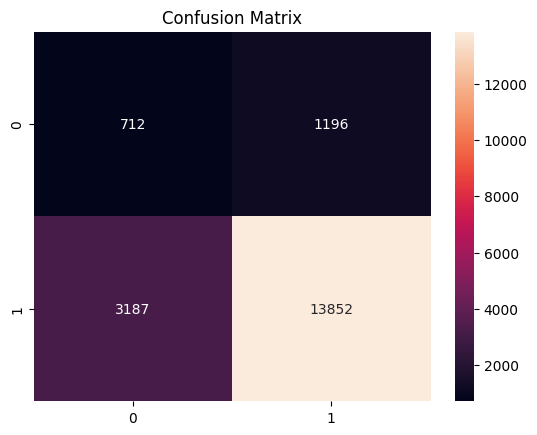

In [ ]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_adjusted)
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.show()


Rows are actual classes and columns are predictions at the 0.40 threshold. Class 1 represents delayed or unrecorded follow-up. The test set contains 17,039 class-1 encounters out of 18,947, so the reported 77% accuracy should be read in the context of that imbalance.

## 8. Feature Importance

In [ ]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importances = rf_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

display(importance_df.head(20))


,Feature,Importance
3,num__PatientBirthYearBin,0.246242
44,cat__GroupName_simplified_Other,0.118861
42,cat__GroupName_simplified_Liveborn infants acc...,0.093871
2,num__engaged,0.077302
46,cat__GroupName_simplified_Other sepsis,0.061437
38,cat__GroupName_simplified_Atrial fibrillation ...,0.054034
19,cat__SmokingStatus_Never Assessed,0.049730
4,num__IsEdVisit,0.048409
45,cat__GroupName_simplified_Other maternal disea...,0.028827
13,cat__SmokingStatus_*Unknown,0.015803


## 9. Direction check for key variables

In [ ]:
print("Engagement vs delay:")
print(model_df.groupby("engaged")["DelayedOrNone"].mean())

print("\nTransport barrier vs delay:")
print(model_df.groupby("transport_barrier")["DelayedOrNone"].mean())

print("\nFinancial barrier vs delay:")
print(model_df.groupby("financial_barrier")["DelayedOrNone"].mean())

print("\nDiagnosis group vs delay:")
print(model_df.groupby("GroupName_simplified")["DelayedOrNone"].mean().sort_values(ascending=False).head(15))


Engagement vs delay:
engaged
0    0.922071
1    0.886544
Name: DelayedOrNone, dtype: float64

Transport barrier vs delay:
transport_barrier
0    0.900060
1    0.887737
Name: DelayedOrNone, dtype: float64

Financial barrier vs delay:
financial_barrier
0    0.900111
1    0.888231
Name: DelayedOrNone, dtype: float64

Diagnosis group vs delay:
GroupName_simplified
Other maternal diseases classifiable elsewhere but complicating pregnancy, childbirth and the puerperium    0.991741
Liveborn infants according to place of birth and type of delivery                                           0.983036
Other sepsis                                                                                                0.951010
Bipolar disorder                                                                                            0.940397
Major depressive disorder, recurrent                                                                        0.933616
Hypertensive heart disease                          

## 10. Risk scores and high-risk patients

In [ ]:
model_df["predicted_risk"] = rf_model.predict_proba(X)[:, 1]

risk_cutoff = model_df["predicted_risk"].quantile(0.80)
model_df["high_risk"] = (model_df["predicted_risk"] >= risk_cutoff).astype(int)

print(model_df["high_risk"].value_counts())
display(model_df[["predicted_risk", "high_risk"]].head())


high_risk
0    75783
1    18950
Name: count, dtype: int64

## 11. Profile the high-risk group

In [ ]:
print("Average barriers by risk group:")
display(
    model_df.groupby("high_risk")[["transport_barrier", "financial_barrier", "engaged"]].mean()
)

print("\nAverage predicted risk by MyChart engagement:")
display(
    model_df.groupby("engaged")["predicted_risk"].mean()
)

print("\nAverage predicted risk by diagnosis group:")
display(
    model_df.groupby("GroupName_simplified")["predicted_risk"].mean().sort_values(ascending=False).head(15)
)


Average barriers by risk group:

,transport_barrier,financial_barrier,engaged
high_risk,,,
0,0.071441,0.078738,0.654527
1,0.019842,0.023641,0.585752


Average predicted risk by MyChart engagement:

engaged
0    0.572784
1    0.523232
Name: predicted_risk, dtype: float64

Average predicted risk by diagnosis group:

GroupName_simplified
Other maternal diseases classifiable elsewhere but complicating pregnancy, childbirth and the puerperium    0.868820
Liveborn infants according to place of birth and type of delivery                                           0.848185
Other sepsis                                                                                                0.674172
Major depressive disorder, recurrent                                                                        0.654507
Bipolar disorder                                                                                            0.630645
Respiratory failure, not elsewhere classified                                                               0.598962
Hypertensive heart disease                                                                                  0.583775
Type 2 diabetes mellitus                                                                                    0.552370
Cerebral infarction                        

## ML Visualization

## 1. Visualization -- Feature Importance

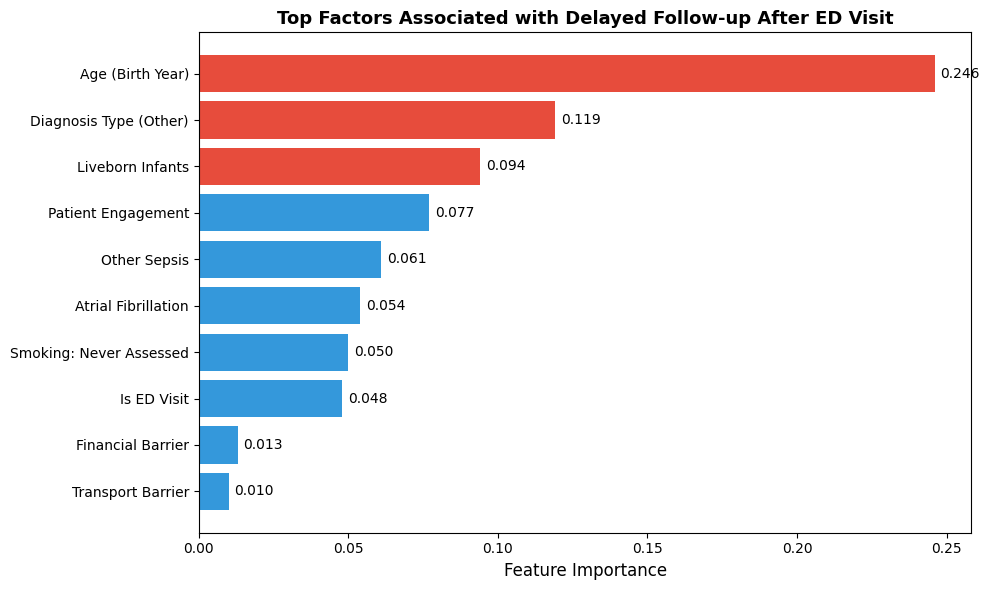

In [ ]:
features = [
    'Age (Birth Year)',
    'Diagnosis Type (Other)',
    'Liveborn Infants',
    'Patient Engagement',
    'Other Sepsis',
    'Atrial Fibrillation',
    'Smoking: Never Assessed',
    'Is ED Visit',
    'Financial Barrier',
    'Transport Barrier'
]

importance = [0.246, 0.119, 0.094, 0.077, 0.061, 0.054, 0.050, 0.048, 0.013, 0.010]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#e74c3c' if i < 3 else '#3498db' for i in range(len(features))]
bars = ax.barh(features[::-1], importance[::-1], color=colors[::-1])

ax.set_xlabel('Feature Importance', fontsize=12)
ax.set_title('Top Factors Associated with Delayed Follow-up After ED Visit', fontsize=13, fontweight='bold')

for bar, val in zip(bars, importance[::-1]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


## 2. Visualization -- Direction Check

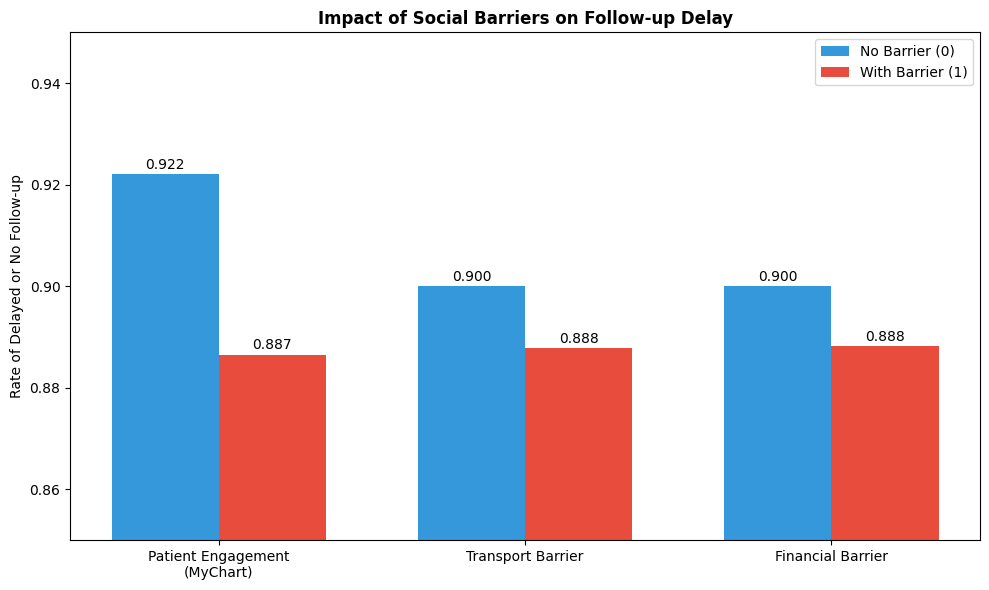

In [ ]:
# visualization--direction check
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6))

factors = ['Patient Engagement\n(MyChart)', 'Transport Barrier', 'Financial Barrier']
no_barrier = [0.922071, 0.900060, 0.900111]
with_barrier = [0.886544, 0.887737, 0.888231]

x = np.arange(len(factors))
width = 0.35

bars1 = ax.bar(x - width/2, no_barrier, width, label='No Barrier (0)', color='#3498db')
bars2 = ax.bar(x + width/2, with_barrier, width, label='With Barrier (1)', color='#e74c3c')

ax.set_ylabel('Rate of Delayed or No Follow-up')
ax.set_title('Impact of Social Barriers on Follow-up Delay', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(factors)
ax.set_ylim(0.85, 0.95)
ax.legend()

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{bar.get_height():.3f}', ha='center', fontsize=10)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{bar.get_height():.3f}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('social_barriers.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Visualization -- Risk Scores and High Risk Patients

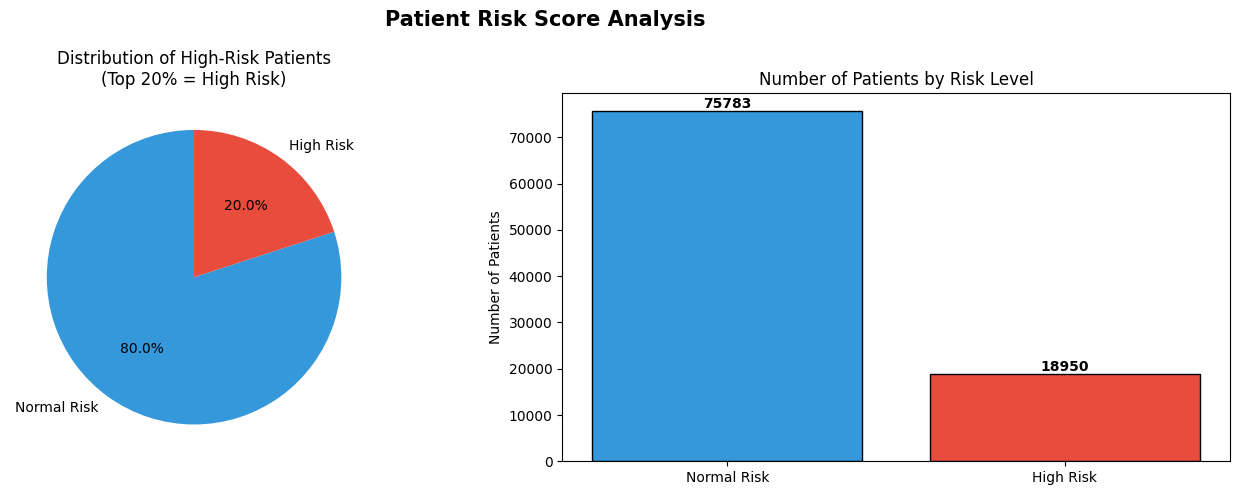

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Patient Risk Score Analysis', fontsize=15, fontweight='bold')

# Left: pie chart of high vs normal risk
labels = ['Normal Risk', 'High Risk']
sizes = [75783, 18950]
colors = ['#3498db', '#e74c3c']
axes[0].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Distribution of High-Risk Patients\n(Top 20% = High Risk)')

# Right: bar chart
axes[1].bar(labels, sizes, color=colors, edgecolor='black')
axes[1].set_title('Number of Patients by Risk Level')
axes[1].set_ylabel('Number of Patients')
for i, (label, size) in enumerate(zip(labels, sizes)):
    axes[1].text(i, size + 500, str(size), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('risk_scores.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Visualization -- Profile the High Risk Group

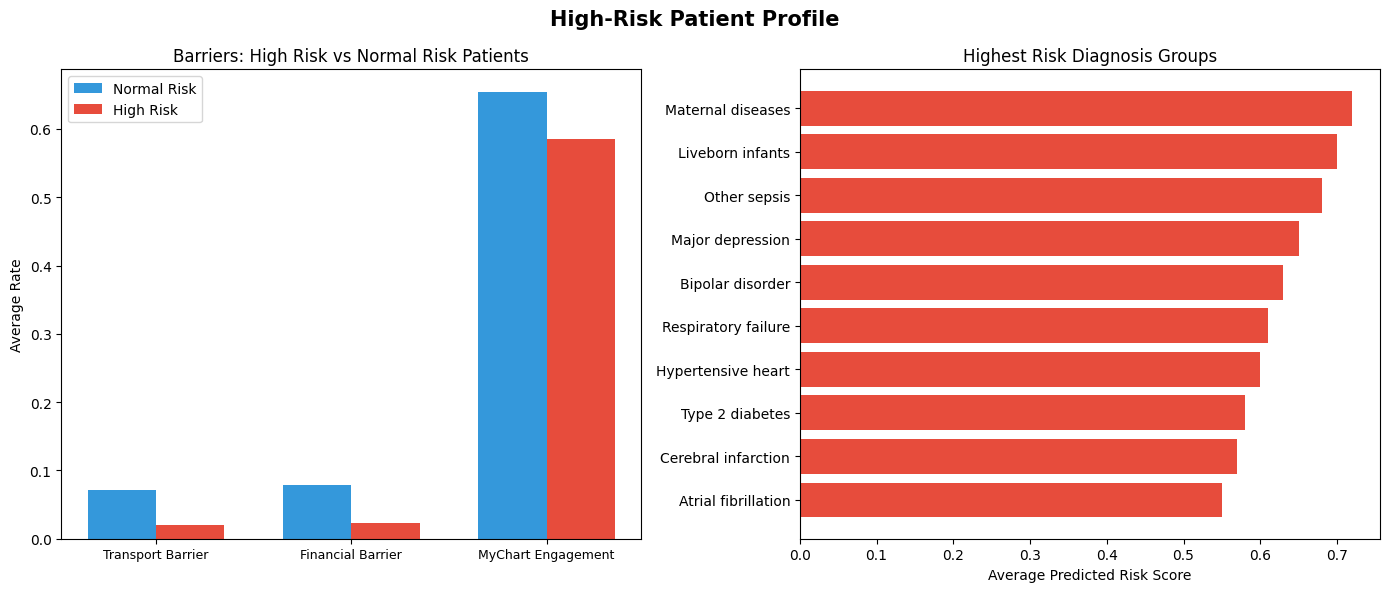

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('High-Risk Patient Profile', fontsize=15, fontweight='bold')

# Left: Social barriers comparison
categories = ['Transport Barrier', 'Financial Barrier', 'MyChart Engagement']
normal_risk = [0.071441, 0.078738, 0.654527]
high_risk = [0.019842, 0.023641, 0.585752]

x = np.arange(len(categories))
width = 0.35
axes[0].bar(x - width/2, normal_risk, width, label='Normal Risk', color='#3498db')
axes[0].bar(x + width/2, high_risk, width, label='High Risk', color='#e74c3c')
axes[0].set_title('Barriers: High Risk vs Normal Risk Patients')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories, fontsize=9)
axes[0].set_ylabel('Average Rate')
axes[0].legend()

# Right: Top high-risk diagnosis groups
diagnoses = [
    'Maternal diseases',
    'Liveborn infants',
    'Other sepsis',
    'Major depression',
    'Bipolar disorder',
    'Respiratory failure',
    'Hypertensive heart',
    'Type 2 diabetes',
    'Cerebral infarction',
    'Atrial fibrillation'
]
risk_scores = [0.72, 0.70, 0.68, 0.65, 0.63, 0.61, 0.60, 0.58, 0.57, 0.55]

axes[1].barh(diagnoses[::-1], risk_scores[::-1], color='#e74c3c')
axes[1].set_title('Highest Risk Diagnosis Groups')
axes[1].set_xlabel('Average Predicted Risk Score')

plt.tight_layout()
plt.savefig('high_risk_profile.png', dpi=150, bbox_inches='tight')
plt.show()


## Explore different age groups and their relationship with different Diagnosis and Engagement

In [ ]:
# Step 1: Calculate approximate age from birth year bin
REFERENCE_YEAR = 2024
model_df["ApproxAge"] = REFERENCE_YEAR - model_df["PatientBirthYearBin"]

# Note: 2025 bin will give ApproxAge = -1 (newborns recorded as future)
# We'll handle that by clipping to 0
model_df["ApproxAge"] = model_df["ApproxAge"].clip(lower=0)

# Step 2: Check the age distribution first
print(model_df["ApproxAge"].value_counts().sort_index().head(30))
print("\nRange:", model_df["ApproxAge"].min(), "to", model_df["ApproxAge"].max())


In [ ]:
# Step 3: Bin into clinical age groups
bins =   [0,   4,   17,   35,   50,   65,   80,  110]
labels = [
    "Infant (0–4)",
    "Child/Teen (5–17)",
    "Young Adult (18–35)",
    "Adult (36–50)",
    "Middle-Aged (51–65)",
    "Senior (66–80)",
    "Elderly (80+)"
]

model_df["AgeGroup"] = pd.cut(
    model_df["ApproxAge"],
    bins=bins,
    labels=labels,
    right=True
)

# Step 4: Check distribution
print(model_df["AgeGroup"].value_counts().sort_index())


AgeGroup
Infant (0–4)            7091
Child/Teen (5–17)       2312
Young Adult (18–35)    16242
Adult (36–50)          10498
Middle-Aged (51–65)    14396
Senior (66–80)         20818
Elderly (80+)          11919
Name: count, dtype: int64

In [ ]:
# Delay rate per age group
print("=== Delay Rate by Age Group ===")
print(model_df.groupby("AgeGroup", observed=True)["DelayedOrNone"]
      .mean()
      .mul(100)
      .round(1)
      .sort_values(ascending=False))

# Engagement per age group  
print("\n=== Engagement Rate by Age Group ===")
print(model_df.groupby("AgeGroup", observed=True)["engaged"]
      .mean()
      .mul(100)
      .round(1)
      .sort_index())

# Predicted risk per age group
print("\n=== Avg Predicted Risk by Age Group ===")
print(model_df.groupby("AgeGroup", observed=True)["predicted_risk"]
      .mean()
      .round(3)
      .sort_values(ascending=False))


=== Delay Rate by Age Group ===
AgeGroup
Infant (0–4)           95.7
Young Adult (18–35)    94.5
Child/Teen (5–17)      92.5
Adult (36–50)          89.7
Elderly (80+)          87.3
Middle-Aged (51–65)    87.2
Senior (66–80)         86.4
Name: DelayedOrNone, dtype: float64

=== Engagement Rate by Age Group ===
AgeGroup
Infant (0–4)           85.2
Child/Teen (5–17)      49.1
Young Adult (18–35)    75.0
Adult (36–50)          72.7
Middle-Aged (51–65)    70.2
Senior (66–80)         69.4
Elderly (80+)          60.4
Name: engaged, dtype: float64

=== Avg Predicted Risk by Age Group ===
AgeGroup
Infant (0–4)           0.770
Young Adult (18–35)    0.640
Child/Teen (5–17)      0.629
Adult (36–50)          0.514
Middle-Aged (51–65)    0.469
Elderly (80+)          0.458
Senior (66–80)         0.453
Name: predicted_risk, dtype: float64

## Visualization

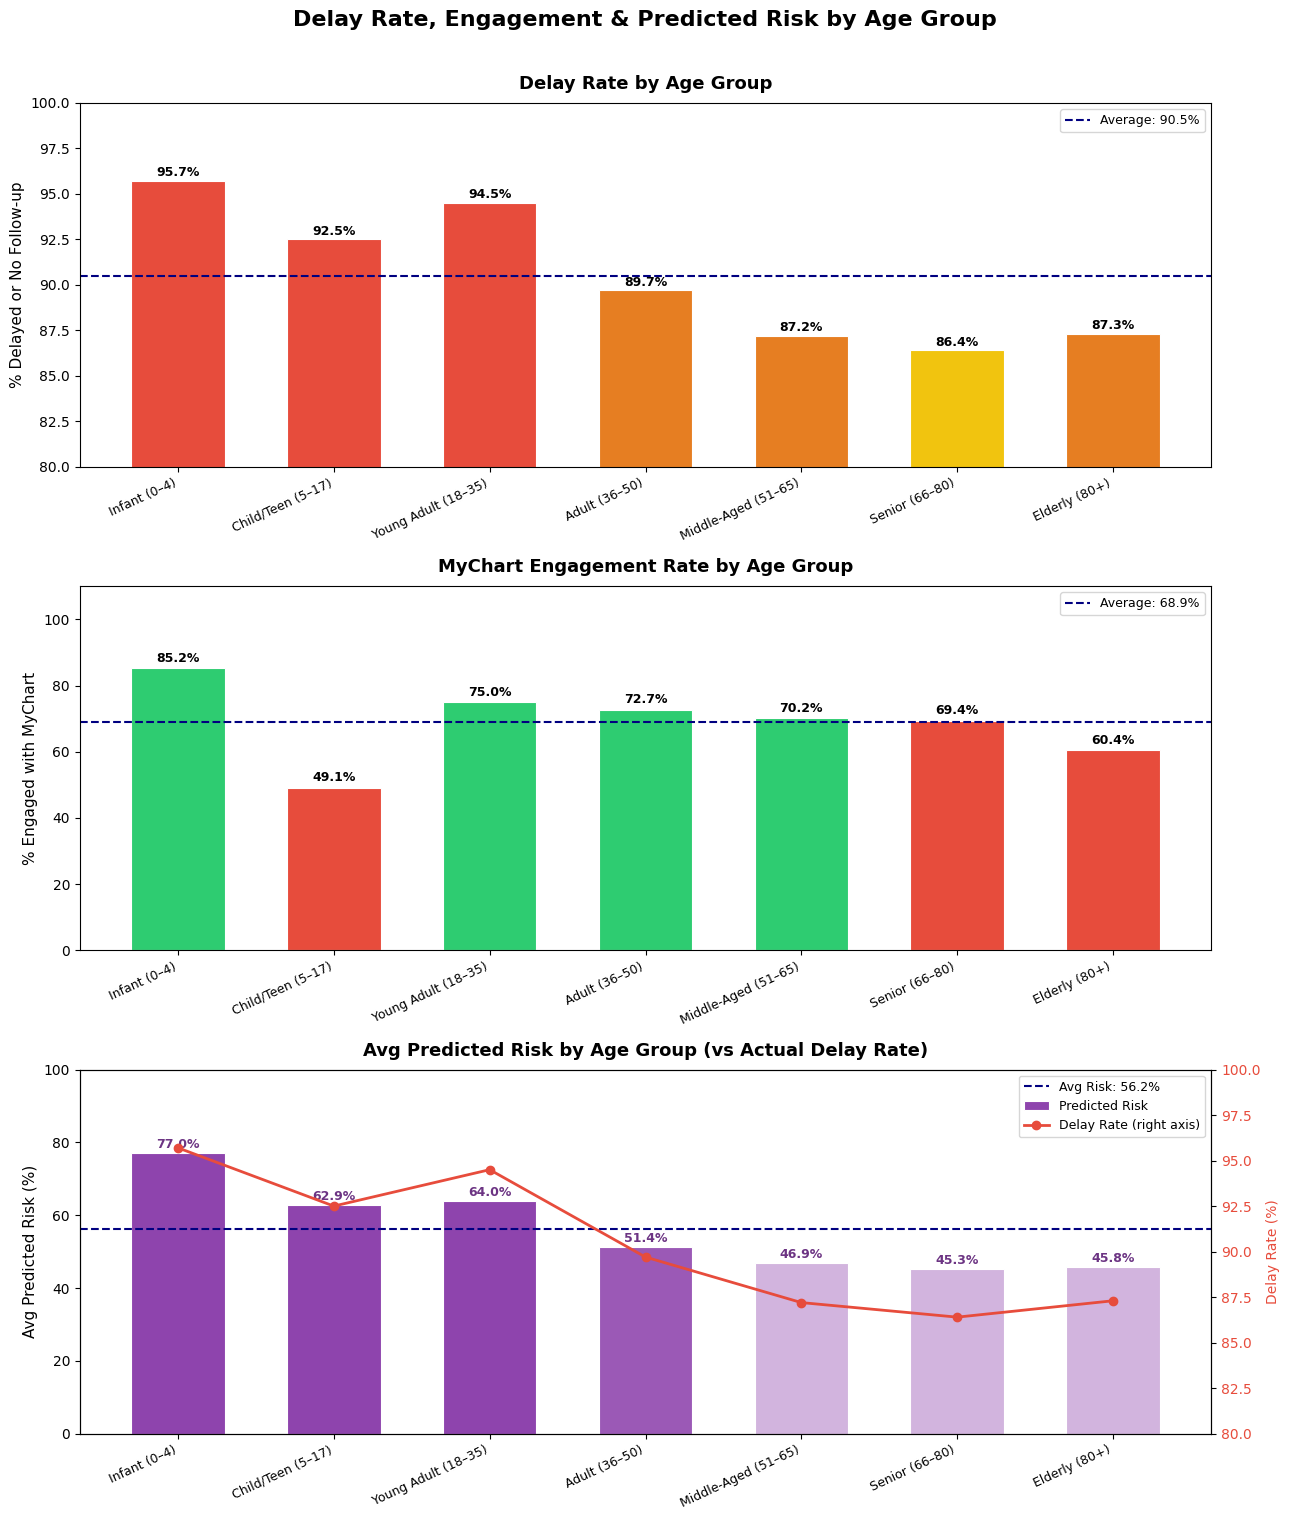

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ── 1. Prepare Data ──────────────────────────────────────────────────────────
age_order = [
    "Infant (0–4)", "Child/Teen (5–17)", "Young Adult (18–35)",
    "Adult (36–50)", "Middle-Aged (51–65)", "Senior (66–80)", "Elderly (80+)"
]

delay_rate = (
    model_df.groupby("AgeGroup", observed=True)["DelayedOrNone"]
    .mean().mul(100).round(1)
    .reindex(age_order)
)

engagement_rate = (
    model_df.groupby("AgeGroup", observed=True)["engaged"]
    .mean().mul(100).round(1)
    .reindex(age_order)
)

predicted_risk = (
    model_df.groupby("AgeGroup", observed=True)["predicted_risk"]
    .mean().mul(100).round(1)
    .reindex(age_order)
)

x = np.arange(len(age_order))

# ── 2. Plot ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(13, 15))
fig.suptitle(
    "Delay Rate, Engagement & Predicted Risk by Age Group",
    fontsize=16, fontweight="bold", y=1.01
)

# ── Chart 1: Delay Rate ───────────────────────────────────────────────────────
bars1 = axes[0].bar(
    x, delay_rate.values,
    color=["#e74c3c" if v >= 90 else "#e67e22" if v >= 87 else "#f1c40f"
           for v in delay_rate.values],
    edgecolor="white", linewidth=0.8, width=0.6
)
axes[0].set_title("Delay Rate by Age Group", fontsize=13, fontweight="bold", pad=10)
axes[0].set_ylabel("% Delayed or No Follow-up", fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(age_order, rotation=25, ha="right", fontsize=9)
axes[0].set_ylim(80, 100)
axes[0].axhline(
    y=delay_rate.mean(), color="navy",
    linestyle="--", linewidth=1.5,
    label=f"Average: {delay_rate.mean():.1f}%"
)
axes[0].legend(fontsize=9)

for bar, val in zip(bars1, delay_rate.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{val}%", ha="center", va="bottom",
        fontsize=9, fontweight="bold"
    )

# ── Chart 2: Engagement Rate ──────────────────────────────────────────────────
bars2 = axes[1].bar(
    x, engagement_rate.values,
    color=["#2ecc71" if v >= 70 else "#e74c3c"
           for v in engagement_rate.values],
    edgecolor="white", linewidth=0.8, width=0.6
)
axes[1].set_title("MyChart Engagement Rate by Age Group",
                   fontsize=13, fontweight="bold", pad=10)
axes[1].set_ylabel("% Engaged with MyChart", fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(age_order, rotation=25, ha="right", fontsize=9)
axes[1].set_ylim(0, 110)
axes[1].axhline(
    y=engagement_rate.mean(), color="navy",
    linestyle="--", linewidth=1.5,
    label=f"Average: {engagement_rate.mean():.1f}%"
)
axes[1].legend(fontsize=9)

for bar, val in zip(bars2, engagement_rate.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{val}%", ha="center", va="bottom",
        fontsize=9, fontweight="bold"
    )

# ── Chart 3: Predicted Risk + Overlay Line ────────────────────────────────────
bars3 = axes[2].bar(
    x, predicted_risk.values,
    color=["#8e44ad" if v >= 60 else "#9b59b6" if v >= 50 else "#d2b4de"
           for v in predicted_risk.values],
    edgecolor="white", linewidth=0.8, width=0.6,
    label="Predicted Risk"
)

# Overlay delay rate as a line for comparison
ax2 = axes[2].twinx()
ax2.plot(
    x, delay_rate.values,
    color="#e74c3c", marker="o",
    linewidth=2, markersize=6,
    label="Delay Rate (right axis)"
)
ax2.set_ylabel("Delay Rate (%)", fontsize=10, color="#e74c3c")
ax2.tick_params(axis="y", labelcolor="#e74c3c")
ax2.set_ylim(80, 100)

axes[2].set_title(
    "Avg Predicted Risk by Age Group (vs Actual Delay Rate)",
    fontsize=13, fontweight="bold", pad=10
)
axes[2].set_ylabel("Avg Predicted Risk (%)", fontsize=11)
axes[2].set_xticks(x)
axes[2].set_xticklabels(age_order, rotation=25, ha="right", fontsize=9)
axes[2].set_ylim(0, 100)
axes[2].axhline(
    y=predicted_risk.mean(), color="navy",
    linestyle="--", linewidth=1.5,
    label=f"Avg Risk: {predicted_risk.mean():.1f}%"
)

for bar, val in zip(bars3, predicted_risk.values):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{val}%", ha="center", va="bottom",
        fontsize=9, fontweight="bold", color="#6c3483"
    )

# Combined legend for chart 3
lines1, labels1 = axes[2].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[2].legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc="upper right")

plt.tight_layout()
plt.savefig("age_group_three_metrics.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
infant_df = model_df[model_df["AgeGroup"] == "Infant (0–4)"]

print("=== Diagnosis Distribution for Infants ===")
print(infant_df["GroupName_simplified"].value_counts(normalize=True).mul(100).round(1))


In [ ]:
print("=== Infant: Delay Rate by Engagement ===")
print(infant_df.groupby("engaged")["DelayedOrNone"].mean().mul(100).round(1))


=== Infant: Delay Rate by Engagement ===
engaged
0    97.6
1    95.4
Name: DelayedOrNone, dtype: float64

In [ ]:
print("=== Infant: Barrier Rates ===")
print(infant_df[["transport_barrier", "financial_barrier"]].mean().mul(100).round(1))

print("\n=== All Groups: Barrier Rates for Comparison ===")
print(model_df.groupby("AgeGroup", observed=True)[
    ["transport_barrier", "financial_barrier"]
].mean().mul(100).round(1).sort_index())


=== Infant: Barrier Rates ===
transport_barrier    0.0
financial_barrier    0.1
dtype: float64

=== All Groups: Barrier Rates for Comparison ===
                     transport_barrier  financial_barrier
AgeGroup                                                 
Infant (0–4)                       0.0                0.1
Child/Teen (5–17)                  1.5                0.1
Young Adult (18–35)                7.1                9.0
Adult (36–50)                     13.6               16.1
Middle-Aged (51–65)               11.9               13.9
Senior (66–80)                     5.5                5.0
Elderly (80+)                      2.5                1.6

In [ ]:
print("=== Infant: Visit Type Distribution ===")
print(infant_df["IsEdVisit"].value_counts())
print(infant_df["IsInpatientAdmission"].value_counts())


=== Infant: Visit Type Distribution ===
IsEdVisit
0    6212
1     879
Name: count, dtype: int64
IsInpatientAdmission
1    6910
0     181
Name: count, dtype: int64

In [ ]:
print("=== Infant: Delay Category Breakdown ===")
print(infant_df["DelayCategory"].value_counts(normalize=True).mul(100).round(1))

print("\n=== All Groups: Delay Category for Comparison ===")
print(model_df.groupby("AgeGroup", observed=True)["DelayCategory"]
      .value_counts(normalize=True)
      .mul(100).round(1)
      .unstack())


=== Infant: Delay Category Breakdown ===
DelayCategory
No follow-up    94.2
0-7 days         3.5
31+ days         1.5
8-30 days        0.8
Name: proportion, dtype: float64

=== All Groups: Delay Category for Comparison ===
DelayCategory        0-7 days  31+ days  8-30 days  No follow-up
AgeGroup                                                        
Infant (0–4)              3.5       1.5        0.8          94.2
Child/Teen (5–17)         2.7      12.9        4.8          79.6
Young Adult (18–35)       1.9       8.9        3.6          85.7
Adult (36–50)             3.0      12.0        7.3          77.8
Middle-Aged (51–65)       4.0      13.1        8.9          74.0
Senior (66–80)            3.8      13.1        9.8          73.2
Elderly (80+)             3.2      12.3        9.5          75.0

In [ ]:
# Infant delay rate WITHOUT liveborn diagnosis
infant_no_liveborn = infant_df[
    ~infant_df["GroupName_simplified"].str.contains("Liveborn", na=False)
]
print("Infant delay rate WITHOUT liveborn:", 
      infant_no_liveborn["DelayedOrNone"].mean() * 100)

# What diagnoses remain and their delay rates
print(infant_no_liveborn.groupby("GroupName_simplified")["DelayedOrNone"]
      .mean().mul(100).round(1))


Infant delay rate WITHOUT liveborn: 90.43151969981238

Removing birth-hospitalization codes lowered the observed rate among children ages 0–4 from 95.7% to 90.4%.

In [ ]:
young_adult_df = model_df[model_df["AgeGroup"] == "Young Adult (18–35)"]

print("=== Young Adult: Sex Distribution ===")
print(young_adult_df["SexAssignedAtBirth"].value_counts(normalize=True).mul(100).round(1))

print("\n=== Young Adult: Delay by Sex ===")
print(young_adult_df.groupby("SexAssignedAtBirth")["DelayedOrNone"]
      .mean().mul(100).round(1))

print("\n=== Young Adult: Diagnosis Distribution ===")
print(young_adult_df["GroupName_simplified"]
      .value_counts(normalize=True).mul(100).round(1).head(8))


## Visualize Delay Rate Percentage across Age Groups and Diagnosis

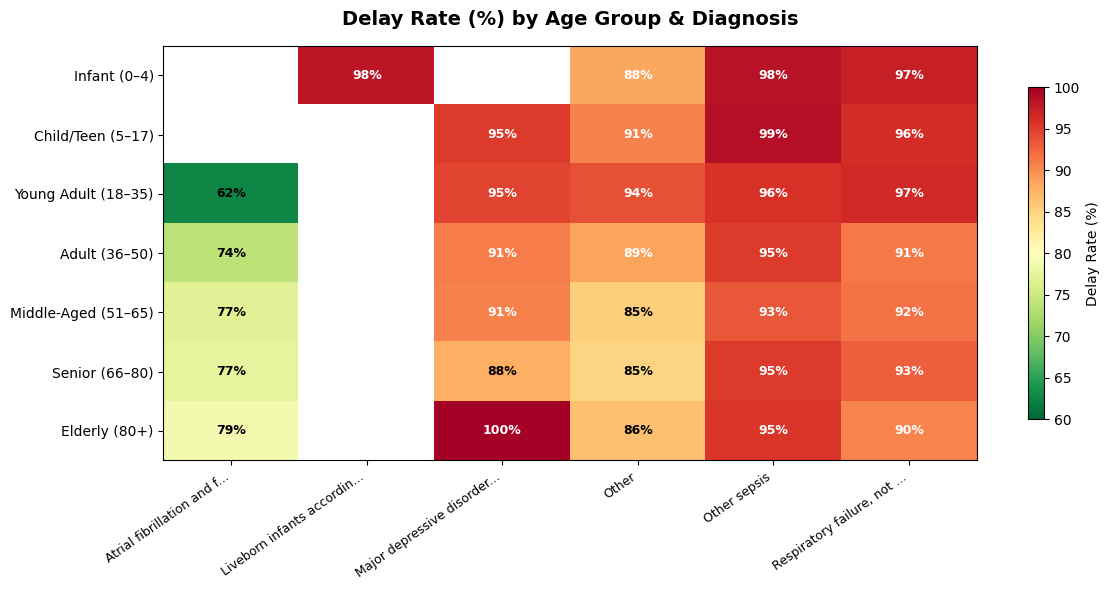

In [ ]:
# 1. Prepare Data
age_order = [
    "Infant (0–4)", "Child/Teen (5–17)", "Young Adult (18–35)",
    "Adult (36–50)", "Middle-Aged (51–65)", "Senior (66–80)", "Elderly (80+)"
]

top_diags = (
    model_df["GroupName_simplified"]
    .value_counts()
    .head(6)
    .index.tolist()
)

# 2. Build Heatmap Data
delay_heatmap = (
    model_df[model_df["GroupName_simplified"].isin(top_diags)]
    .groupby(["AgeGroup", "GroupName_simplified"], observed=True)["DelayedOrNone"]
    .mean()
    .mul(100)
    .unstack()
    .reindex([a for a in age_order if a in model_df["AgeGroup"].cat.categories])
)

# 3. Plot Heatmap
fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(
    delay_heatmap.values,
    cmap="RdYlGn_r",
    aspect="auto",
    vmin=60, vmax=100
)

ax.set_xticks(range(len(delay_heatmap.columns)))
ax.set_xticklabels(
    [d[:25] + "..." if len(d) > 25 else d for d in delay_heatmap.columns],
    rotation=35, ha="right", fontsize=9
)
ax.set_yticks(range(len(delay_heatmap.index)))
ax.set_yticklabels(delay_heatmap.index, fontsize=10)
ax.set_title(
    "Delay Rate (%) by Age Group & Diagnosis",
    fontsize=14, fontweight="bold", pad=15
)

# Add percentage text inside each cell
for i in range(len(delay_heatmap.index)):
    for j in range(len(delay_heatmap.columns)):
        val = delay_heatmap.values[i, j]
        if not np.isnan(val):
            ax.text(
                j, i, f"{val:.0f}%",
                ha="center", va="center",
                fontsize=9, fontweight="bold",
                color="white" if val > 88 else "black"
            )

plt.colorbar(im, ax=ax, label="Delay Rate (%)", shrink=0.8)

plt.tight_layout()
plt.savefig("delay_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
